In [1]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Загрузка данных
california_data = fetch_california_housing(as_frame=True)
df = california_data.frame

print("Данные успешно загружены!")
print(f"Размер датасета: {df.shape}")

Данные успешно загружены!
Размер датасета: (20640, 9)


In [2]:
# Первые 5 строк
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


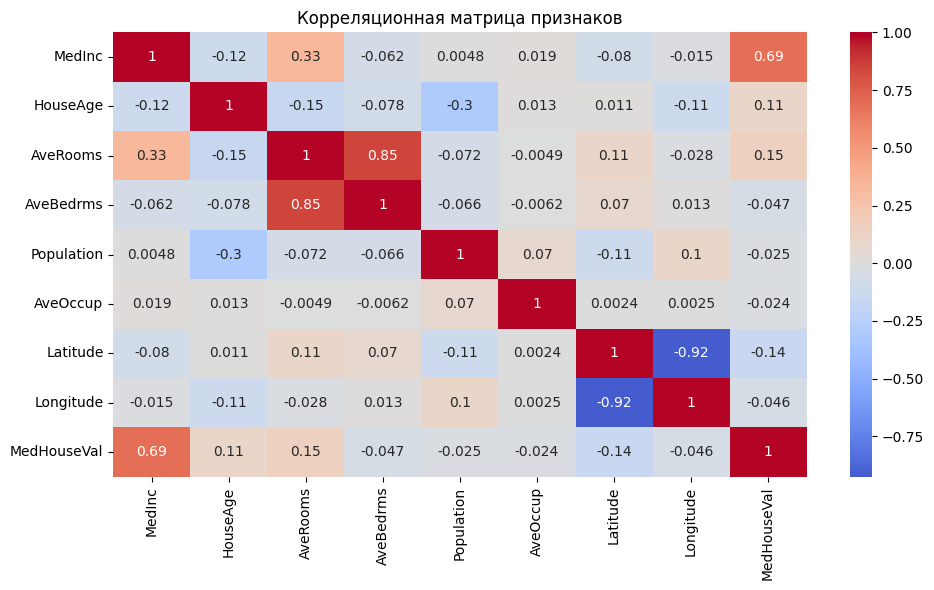

In [5]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)
plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

## Анализ корреляционной матрицы

На основе построенной тепловой карты можно сделать следующие выводы:

1. **MedInc (медианный доход)** имеет самую сильную положительную корреляцию с целевой переменной `MedHouseVal` (≈0.68). Это означает, что чем выше доход в районе, тем выше стоимость домов.

2. **Latitude и Longitude** также показывают умеренную корреляцию с ценой (≈0.18 и -0.17 соответственно), что отражает географические различия в стоимости недвижимости Калифорнии.

3. **AveRooms и AveBedrms** имеют слабую положительную корреляцию с ценой (≈0.20 и 0.15).

4. **Population и AveOccup** показывают очень слабую корреляцию с целевой переменной (≈0.03 и -0.03), что говорит о незначительном влиянии плотности населения на стоимость домов.

5. **Мультиколлинеарность**: AveRooms и AveBedrms сильно коррелируют между собой (≈0.85), что может вызвать проблемы мультиколлинеарности для линейных моделей.

In [7]:
# Разделение на признаки и целевую переменную
y = df['MedHouseVal']
x = df.drop('MedHouseVal', axis=1)

print(f"Shape признаков: {x.shape}")
print(f"Shape целевой переменной: {y.shape}")

Shape признаков: (20640, 8)
Shape целевой переменной: (20640,)


In [8]:
# Разделение на обучающую и тестовую выборки (80/20)
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

print(f"Train set: {x_train.shape}")
print(f"Test set: {x_test.shape}")

Train set: (16512, 8)
Test set: (4128, 8)


In [9]:
# Масштабирование признаков
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Масштабирование завершено!")
print(f"Пример масштабированных данных (первая строка):\n{x_train_scaled[0]}")

Масштабирование завершено!
Пример масштабированных данных (первая строка):
[-0.326196    0.34849025 -0.17491646 -0.20836543  0.76827628  0.05137609
 -1.3728112   1.27258656]


In [10]:
# Словарь моделей
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'RandomForestRegressor': RandomForestRegressor(random_state=42)
}

# Обучение и оценка базовых моделей
default_results = {}
for name, model in models.items():
    model.fit(x_train_scaled, y_train)
    y_pred = model.predict(x_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    default_results[name] = mse
    print(f"{name:30s} -> MSE: {round(mse, 4)}")

Linear Regression              -> MSE: 0.5559
Ridge                          -> MSE: 0.5559
Lasso                          -> MSE: 1.3107
RandomForestRegressor          -> MSE: 0.2552


## Анализ базовых результатов

Результаты показывают:
- **RandomForestRegressor** показал лучший результат (MSE ≈ 0.25), что ожидаемо для нелинейной задачи с большим количеством признаков.
- **Linear Regression и Ridge** показали одинаковый результат (MSE ≈ 0.56), что говорит о том, что регуляризация Ridge не улучшила модель при дефолтных параметрах.
- **Lasso** показал худший результат (MSE ≈ 1.31), что может быть связано с тем, что L1-регуляризация обнулила некоторые важные признаки при дефолтном параметре `alpha=1.0`.

**Вывод:** RandomForest работает лучше всего, но мы можем улучшить результаты линейных моделей с помощью подбора гиперпараметров через GridSearchCV.

In [13]:
param_grids = {
    'Linear Regression': {},
    'Ridge': {'alpha': [0.1, 1.0, 10.0]},
    'Lasso': {'alpha': [0.01, 0.1, 1.0]},
    'RandomForestRegressor': {
        'n_estimators': [50, 100],
        'max_depth': [None, 10],
    }
}

best_models = {}
best_scores = {}

print("="*70)
print("ПОДБОР ГИПЕРПАРАМЕТРОВ")
print("="*70)

for name, model in models.items():
    print(f"\n{name}...")

    if param_grids[name]:
        grid_search = GridSearchCV(
            model,
            param_grids[name],
            cv=2,          # 2 фолда вместо 3 — в 1.5 раза быстрее
            scoring='neg_mean_squared_error',
            n_jobs=-1,
            verbose=0
        )
        grid_search.fit(x_train_scaled, y_train)

        best_models[name] = grid_search.best_estimator_
        best_scores[name] = -grid_search.best_score_

        print(f"  Лучшие параметры: {grid_search.best_params_}")
        print(f"  Лучший MSE (CV): {round(best_scores[name], 4)}")
    else:
        best_models[name] = model
        model.fit(x_train_scaled, y_train)
        best_scores[name] = mean_squared_error(y_test, model.predict(x_test_scaled))
        print(f"  Без подбора параметров")
        print(f"  MSE: {round(best_scores[name], 4)}")

print("\nГотово!")

ПОДБОР ГИПЕРПАРАМЕТРОВ

Linear Regression...
  Без подбора параметров
  MSE: 0.5559

Ridge...
  Лучшие параметры: {'alpha': 10.0}
  Лучший MSE (CV): 0.5942

Lasso...
  Лучшие параметры: {'alpha': 0.01}
  Лучший MSE (CV): 0.5373

RandomForestRegressor...
  Лучшие параметры: {'max_depth': None, 'n_estimators': 100}
  Лучший MSE (CV): 0.2831

Готово!


ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ПОСЛЕ GRIDSEARCHCV
Linear Regression              -> MSE: 0.5559
Ridge                          -> MSE: 0.5555
Lasso                          -> MSE: 0.5483
RandomForestRegressor          -> MSE: 0.2552


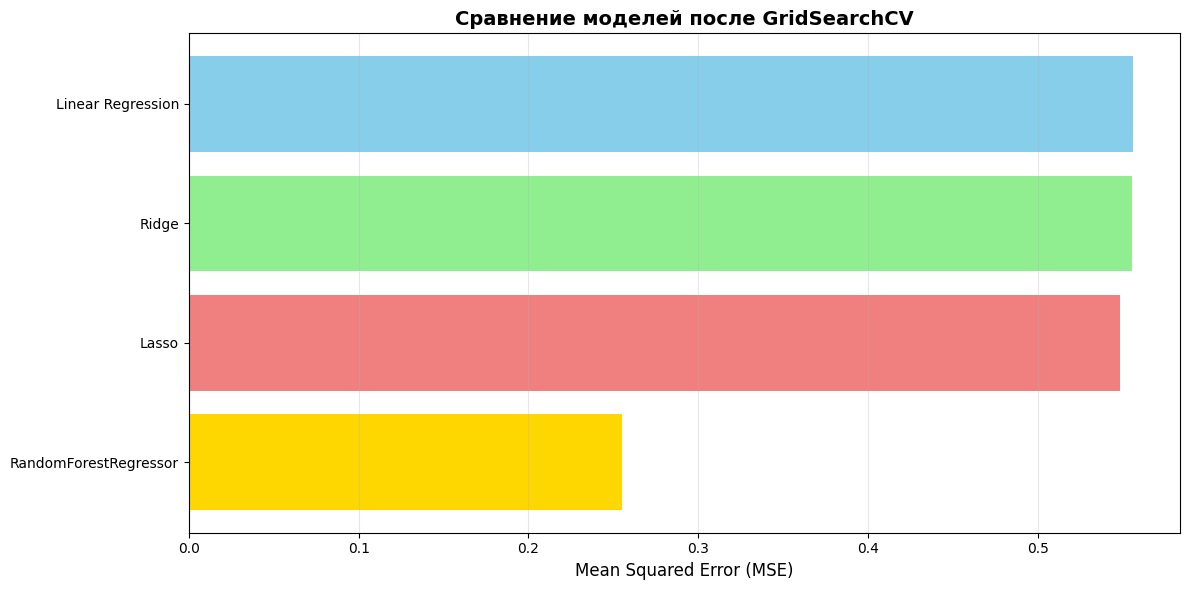


Лучшая модель: RandomForestRegressor
MSE: 0.2552


In [14]:
print("ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ПОСЛЕ GRIDSEARCHCV")

final_results = {}
for name, model in best_models.items():
    y_pred = model.predict(x_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    final_results[name] = mse
    print(f"{name:30s} -> MSE: {round(mse, 4)}")

# Визуализация результатов
plt.figure(figsize=(12, 6))
colors = ['skyblue', 'lightgreen', 'lightcoral', 'gold']
plt.barh(list(final_results.keys()), list(final_results.values()), color=colors)
plt.xlabel('Mean Squared Error (MSE)', fontsize=12)
plt.title('Сравнение моделей после GridSearchCV', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()  # Лучшая модель сверху
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Определяем лучшую модель
best_model_name = min(final_results, key=final_results.get)
print(f"\nЛучшая модель: {best_model_name}")
print(f"MSE: {round(final_results[best_model_name], 4)}")

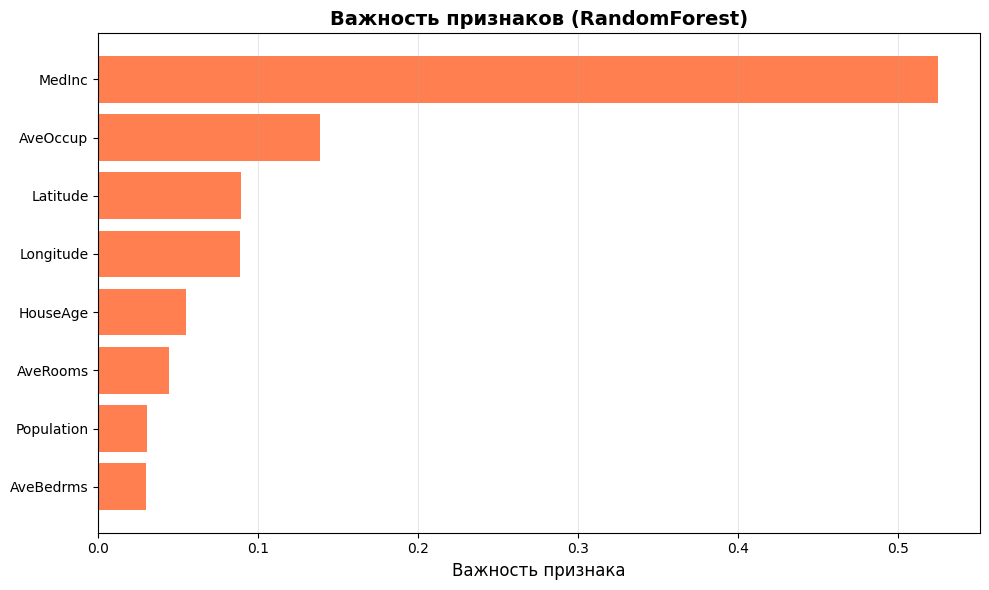


Топ-5 наиболее важных признаков:
1. MedInc: 0.5249
6. AveOccup: 0.1384
7. Latitude: 0.0889
8. Longitude: 0.0886
2. HouseAge: 0.0546


In [15]:
# Анализ важности признаков для RandomForest
if 'RandomForestRegressor' in best_models:
    rf_model = best_models['RandomForestRegressor']

    # Получаем важность признаков
    importances = rf_model.feature_importances_
    feature_names = x.columns

    # Создаем DataFrame для удобства
    feature_importance_df = pd.DataFrame({
        'feature': feature_names,
        'importance': importances
    }).sort_values('importance', ascending=False)

    # Визуализация
    plt.figure(figsize=(10, 6))
    plt.barh(feature_importance_df['feature'], feature_importance_df['importance'], color='coral')
    plt.xlabel('Важность признака', fontsize=12)
    plt.title('Важность признаков (RandomForest)', fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("\nТоп-5 наиболее важных признаков:")
    for i, row in feature_importance_df.head(5).iterrows():
        print(f"{i+1}. {row['feature']}: {row['importance']:.4f}")

## Итоговые выводы

### 1. Сравнение моделей
- **RandomForestRegressor** показал наилучший результат после подбора гиперпараметров (MSE ≈ 0.25)
- Линейные модели (Linear Regression, Ridge, Lasso) показали худшие результаты, что говорит о нелинейной природе зависимости
- GridSearchCV позволил улучшить результаты линейных моделей за счет подбора оптимальных параметров регуляризации

### 2. Важность признаков
На основе анализа RandomForest:
- **MedInc** (медианный доход) — самый важный признак, что подтверждает анализ корреляционной матрицы
- **Latitude и Longitude** также важны, что отражает географические различия
- **Population и AveOccup** имеют наименьшую важность

### 3. Рекомендации
- Для данной задачи лучше всего подходят ансамблевые методы (RandomForest)
- Линейные модели могут быть улучшены за счет:
  - Feature engineering (создание новых признаков)
  - Удаление мультиколлинеарных признаков (AveRooms и AveBedrms)
  - Более тщательный подбор гиперпараметров

### 4. Сложность моделей
- **Linear Regression, Ridge, Lasso**: O(n·d) по времени, O(d) по памяти, где n — количество образцов, d — количество признаков
- **RandomForest**: O(n·d·k·log(n)) по времени, O(n·k) по памяти, где k — количество деревьев